## Intro

# Seoul Bike Sharing Demand Prediction

Seoul runs a public bike rental system across the city. To keep users happy, bikes need to be available when and where people want them. If there are too few, customers can't rent one. If there are too many, bikes sit unused. Knowing how many bikes will be needed each hour helps the city plan how many to put out and when to move them between stations.

This notebook uses hourly rental data from Seoul (Kaggle "Seoul Bike Sharing Demand Prediction" dataset), from December 2017 to November 2018. That's 8,760 hours in total. For each hour, we have:
- **Time:** date, hour, season and whether it was a holiday.
- **Weather:** temperature, humidity, wind speed, visibility, dew point, solar radiation, rainfall and snowfall.
- **Whether the system was working:** on 295 hours the system was closed and no bikes were rented. We remove these hours, which leaves 8,465.

## Problem

**Main question:** Can we predict how many bikes will be rented in a given hour, based on the time and the weather?

**Target:** `Rented Bike Count`, the number of bikes rented in that hour.
- On average, 729 bikes are rented per hour. The median is 542 and the busiest hour reached 3,556.
- Demand changes a lot during the day, with peaks around 8am and 6pm, and across the seasons.

This is a regression problem: we predict a number, not a category.

**How we measure success:**
- **Baseline:** a model that always predicts the average (729 bikes) has an R² of 0. A useful model has to beat this.
- **R²:** how much of the change in demand the model explains (1 = perfect, 0 = no better than the average).
- **MAE (mean absolute error):** how many bikes the model is off by, on average.
- **RMSE (root mean squared error):** like MAE, but big misses count more. This matters here, because a big miss at rush hour means empty stations when demand is highest.

We compare models on the test set: a better model has a higher R² and a lower MAE and RMSE.

## Imports

In [166]:
!pip install kagglehub

In [167]:
import matplotlib.pyplot as plt
import os
import kagglehub
import pandas as pd
import numpy as np

In [168]:
# Download the dataset (returns the folder where it was saved)
path = kagglehub.dataset_download("saurabhshahane/seoul-bike-sharing-demand-prediction")

# Load the CSV into a table
df = pd.read_csv(os.path.join(path, "SeoulBikeData.csv"), encoding="latin-1")
df.head()

Using Colab cache for faster access to the 'seoul-bike-sharing-demand-prediction' dataset.


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


## Data prep

In [169]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [170]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [171]:
df["Date in Datetime"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df["Day"] =  df["Date in Datetime"].dt.day
df["Month"] =  df["Date in Datetime"].dt.month
df["Year"] =  df["Date in Datetime"].dt.year
df["Day of the week"] =  df["Date in Datetime"].dt.dayofweek

In [172]:
cat = df.select_dtypes([object])
cat

,Date,Seasons,Holiday,Functioning Day
0,01/12/2017,Winter,No Holiday,Yes
1,01/12/2017,Winter,No Holiday,Yes
2,01/12/2017,Winter,No Holiday,Yes
3,01/12/2017,Winter,No Holiday,Yes
4,01/12/2017,Winter,No Holiday,Yes
...,...,...,...,...
8755,30/11/2018,Autumn,No Holiday,Yes
8756,30/11/2018,Autumn,No Holiday,Yes
8757,30/11/2018,Autumn,No Holiday,Yes
8758,30/11/2018,Autumn,No Holiday,Yes


In [173]:
for c in cat.columns:
  print(cat[c].value_counts(dropna=False))

Date
30/11/2018    24
01/12/2017    24
02/12/2017    24
03/12/2017    24
04/12/2017    24
              ..
18/12/2017    24
17/12/2017    24
16/12/2017    24
15/12/2017    24
14/12/2017    24
Name: count, Length: 365, dtype: int64
Seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64
Holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64
Functioning Day
Yes    8465
No      295
Name: count, dtype: int64


In [174]:
df["Functioning Day"].unique()

array(['Yes', 'No'], dtype=object)

In [175]:
# Since "Functioning Day" == No means they were closed and no bikes were available to rent, we will remove them from the dataset
len(df[df["Functioning Day"] == "No"])

295

In [176]:
df[["Functioning Day", "Rented Bike Count"]].groupby("Functioning Day").sum()

,Rented Bike Count
Functioning Day,
No,0
Yes,6172314


In [177]:
print(df.shape)
prep = df.drop(df[df["Functioning Day"] == "No"].index)
print(prep.shape)

(8760, 19)
(8465, 19)


In [178]:
# Now, we can remove this column altogheter, because it's always yes:
print(prep["Functioning Day"].unique())
prep.drop(["Functioning Day"], axis=1, inplace=True)

['Yes']


## Hyphotesis

In [179]:
prep["Year"].value_counts() # we will remove year from the model. We could try to predict the following year, but there's not enough data to train the model on.

,count
Year,
2018,7721
2017,744


In [180]:
prep.drop(["Year"], axis=1, inplace=True)

In [181]:
cor = prep.select_dtypes([int, float]).corr()
cor["Rented Bike Count"]

,Rented Bike Count
Rented Bike Count,1.000000
Hour,0.425256
Temperature(°C),0.562740
Humidity(%),-0.201973
Wind speed (m/s),0.125022
Visibility (10m),0.212323
Dew point temperature(°C),0.400263
Solar Radiation (MJ/m2),0.273862
Rainfall(mm),-0.128626
Snowfall (cm),-0.151611


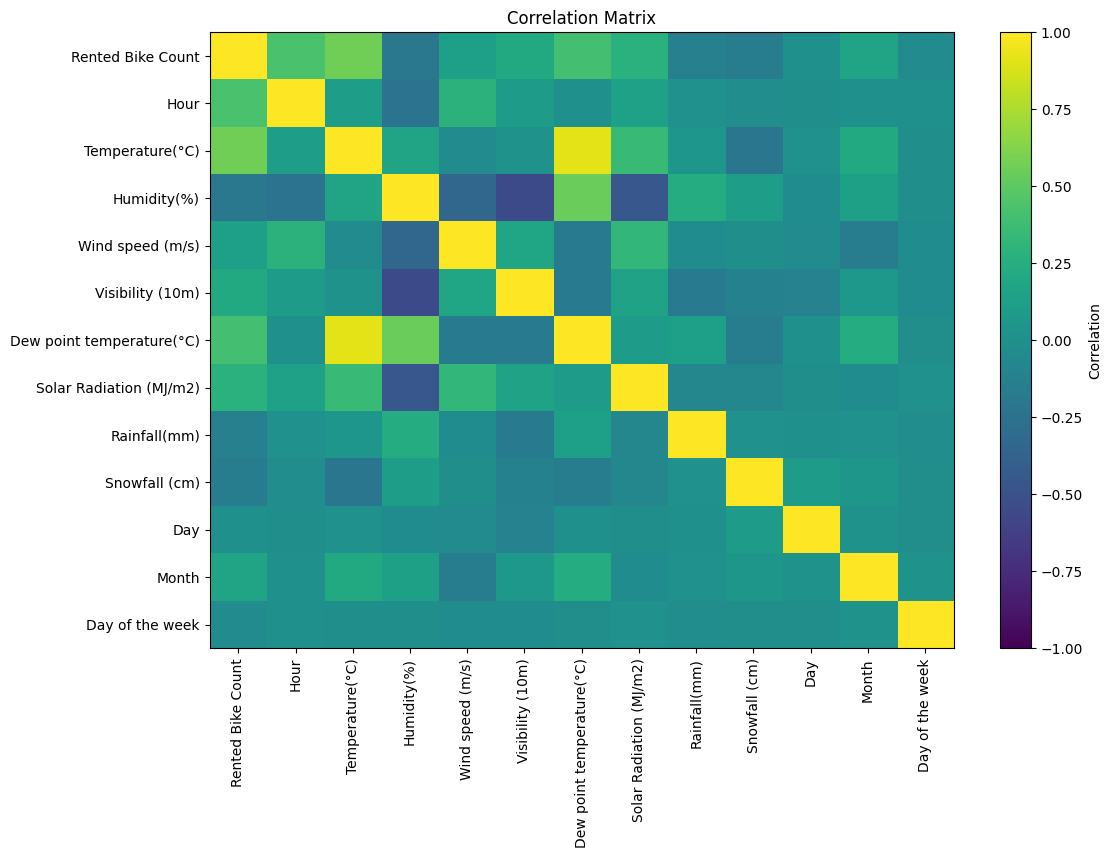

In [182]:
# Now we need to check if the variables have big correlations between themselves, this can confuse the algo and won't add new info:
plt.figure(figsize=(12, 8))
plt.imshow(cor, cmap="viridis", aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(cor.columns)), cor.columns, rotation=90)
plt.yticks(range(len(cor.index)), cor.index)
plt.title("Correlation Matrix")
plt.show()

In [183]:
# Yes, temperature and dew are very correlated - they are basically the same information. I'll remove the Dew one because has less correlation with the target.
# We could delete some others as well, like solar radiation and visibility, because they are high correletaed with Humidity. But we will leave like this for now
prep.drop(["Dew point temperature(°C)"], axis=1, inplace=True)

Since Holiday is binary (Yes or No), let's replace to 1 and 0, instead of one-hot-encode them.
If we did that, we would need to remove one of the columns like:

- df = pd.get_dummies(df["Holiday"], axis=1), drop_first=True)

If we kept it, the two Holiday columns would always add up to 1:

| Day | Holiday_Holiday | Holiday_No Holiday |
|---|---:|---:|
| Christmas | 1 | 0 |
| Normal Tuesday | 0 | 1 |

So the second column adds no new information. If you know one, you know the other. The same goes for the 4 seasons: they always add up to 1.

This is called the dummy trap, also called **perfect multicollinearity**.

In [184]:
prep["Holiday"].value_counts(dropna=False)

,count
Holiday,
No Holiday,8057
Holiday,408


In [185]:
prep["Holiday"] = prep["Holiday"].replace({"Holiday": 1, "No Holiday": 0})
prep["Holiday"].info()

<class 'pandas.core.series.Series'>
Index: 8465 entries, 0 to 8759
Series name: Holiday
Non-Null Count  Dtype
--------------  -----
8465 non-null   int64
dtypes: int64(1)
memory usage: 132.3 KB


/tmp/ipykernel_815/2902313455.py:1: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



In [186]:
prep.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8465 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     8465 non-null   object        
 1   Rented Bike Count        8465 non-null   int64         
 2   Hour                     8465 non-null   int64         
 3   Temperature(°C)          8465 non-null   float64       
 4   Humidity(%)              8465 non-null   int64         
 5   Wind speed (m/s)         8465 non-null   float64       
 6   Visibility (10m)         8465 non-null   int64         
 7   Solar Radiation (MJ/m2)  8465 non-null   float64       
 8   Rainfall(mm)             8465 non-null   float64       
 9   Snowfall (cm)            8465 non-null   float64       
 10  Seasons                  8465 non-null   object        
 11  Holiday                  8465 non-null   int64         
 12  Date in Datetime         8465 non-null 

In [187]:
cat_var = pd.get_dummies(prep.drop(["Date"], axis=1).select_dtypes(object), drop_first=True) # Autumn becomes the baseline, and each season’s coefficient then means “compared with Autumn”.
cat_var

,Seasons_Spring,Seasons_Summer,Seasons_Winter
0,False,False,True
1,False,False,True
2,False,False,True
3,False,False,True
4,False,False,True
...,...,...,...
8755,False,False,False
8756,False,False,False
8757,False,False,False
8758,False,False,False


In [188]:
num = prep.select_dtypes([int, float])
num

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Holiday,Day,Month,Day of the week
0,254,0,-5.2,37,2.2,2000,0.0,0.0,0.0,0,1,12,4
1,204,1,-5.5,38,0.8,2000,0.0,0.0,0.0,0,1,12,4
2,173,2,-6.0,39,1.0,2000,0.0,0.0,0.0,0,1,12,4
3,107,3,-6.2,40,0.9,2000,0.0,0.0,0.0,0,1,12,4
4,78,4,-6.0,36,2.3,2000,0.0,0.0,0.0,0,1,12,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,1003,19,4.2,34,2.6,1894,0.0,0.0,0.0,0,30,11,4
8756,764,20,3.4,37,2.3,2000,0.0,0.0,0.0,0,30,11,4
8757,694,21,2.6,39,0.3,1968,0.0,0.0,0.0,0,30,11,4
8758,712,22,2.1,41,1.0,1859,0.0,0.0,0.0,0,30,11,4


In [189]:
df_final = pd.merge(num, cat_var, left_index=True, right_index=True)
df_cor = df_final.corr()
df_cor["Rented Bike Count"].sort_values()

,Rented Bike Count
Seasons_Winter,-0.458920
Humidity(%),-0.201973
Snowfall (cm),-0.151611
Rainfall(mm),-0.128626
Holiday,-0.070070
Day of the week,-0.034272
Day,0.007644
Seasons_Spring,0.015580
Wind speed (m/s),0.125022
Month,0.167186


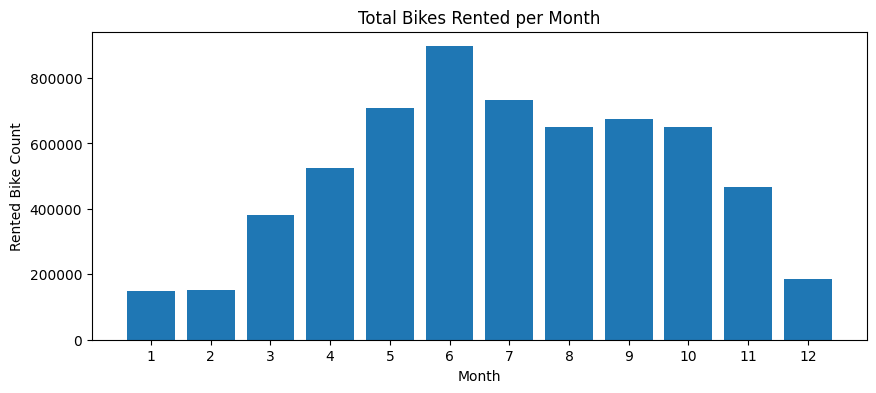

In [190]:
monthly = df_final.groupby("Month")["Rented Bike Count"].sum()

plt.figure(figsize=(10, 4))
plt.bar(monthly.index.astype(str), monthly.values)
plt.title("Total Bikes Rented per Month")
plt.xlabel("Month")
plt.ylabel("Rented Bike Count")
plt.show()

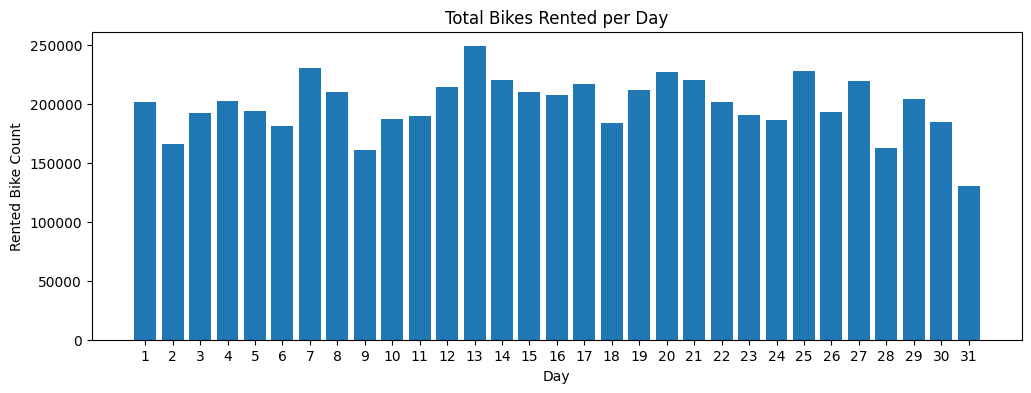

In [191]:
daily = df_final.groupby("Day")["Rented Bike Count"].sum()

plt.figure(figsize=(12, 4))
plt.bar(daily.index.astype(str), daily.values)
plt.title("Total Bikes Rented per Day")
plt.xlabel("Day")
plt.ylabel("Rented Bike Count")
plt.show()

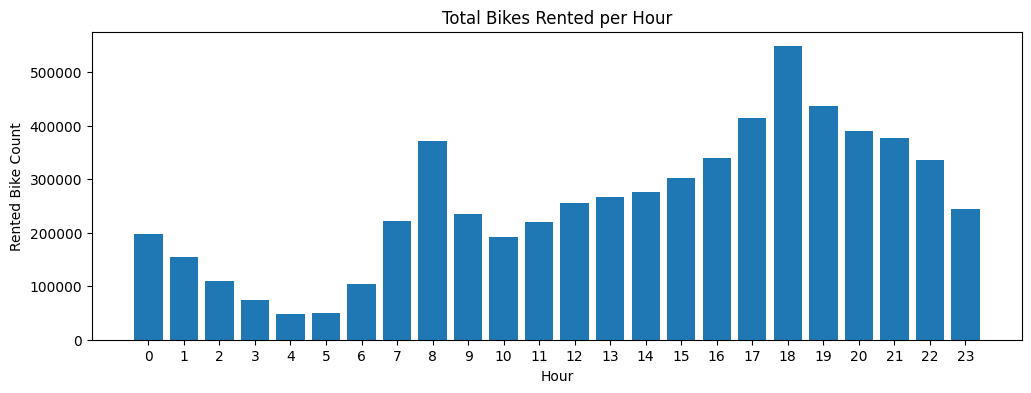

In [192]:
hourly = df_final.groupby("Hour")["Rented Bike Count"].sum()

plt.figure(figsize=(12, 4))
plt.bar(hourly.index.astype(str), hourly.values)
plt.title("Total Bikes Rented per Hour")
plt.xlabel("Hour")
plt.ylabel("Rented Bike Count")
plt.show()

In [193]:
df.shape

(8760, 19)

In [194]:
daily_total = prep[["Date in Datetime", "Rented Bike Count"]].groupby(["Date in Datetime"]).sum().reset_index(names="date")
daily_total

,date,Rented Bike Count
0,2017-12-01,9539
1,2017-12-02,8523
2,2017-12-03,7222
3,2017-12-04,8729
4,2017-12-05,8307
...,...,...
348,2018-11-26,17162
349,2018-11-27,16282
350,2018-11-28,16524
351,2018-11-29,16423


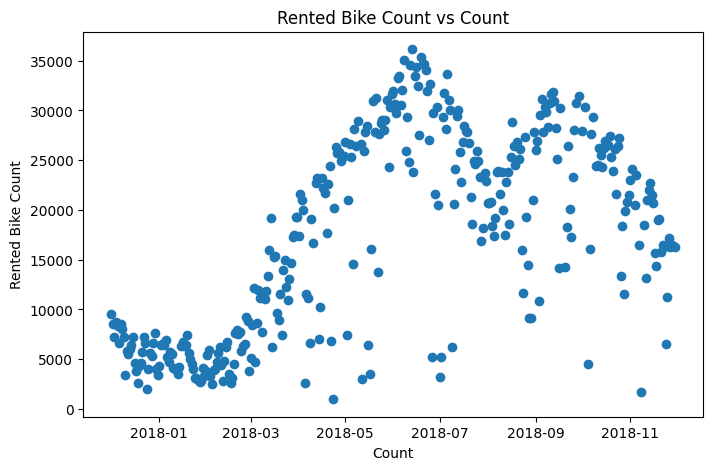

In [195]:
plt.figure(figsize=(8, 5))
plt.scatter(daily_total["date"], daily_total["Rented Bike Count"])
plt.title("Rented Bike Count vs Count")
plt.xlabel("Count")
plt.ylabel("Rented Bike Count")
plt.show()

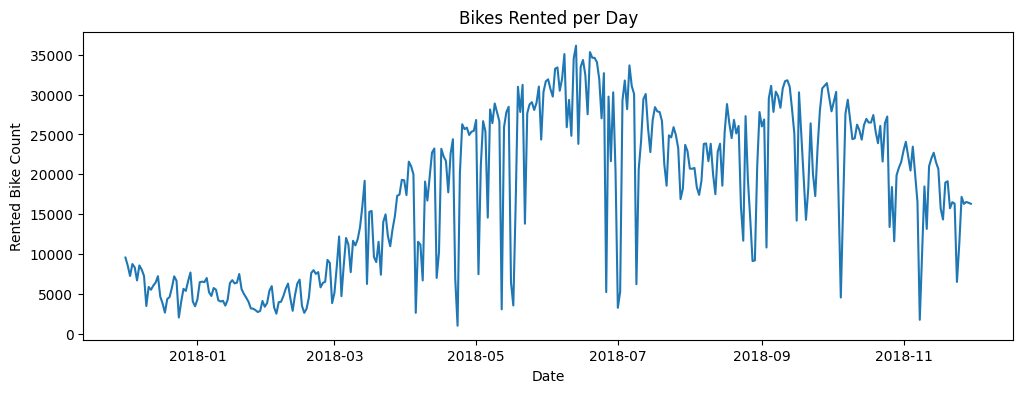

In [196]:
daily_total = prep.groupby("Date in Datetime")["Rented Bike Count"].sum()

plt.figure(figsize=(12, 4))
plt.plot(daily_total.index, daily_total.values)
plt.title("Bikes Rented per Day")
plt.xlabel("Date")
plt.ylabel("Rented Bike Count")
plt.show()

## Model

In [197]:
# Let's start with linear regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import numpy as np

X = df_final.drop(["Rented Bike Count"], axis=1)
y = df_final["Rented Bike Count"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)

print(f"Train score: {r2_train}")
print(f"Test score: {r2_test}")

print('-'*20)

print('Intercept: {}'.format(model.intercept_))
print("Coeficiente: {}".format(model.coef_))
print('RMSE: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))
print('R2: {}'.format(r2_train))
print('R2 test: {}'.format(r2_test))

Train score: 0.5399298207386166
Test score: 0.5569613679486789
--------------------
Intercept: 799.7393988430724
Coeficiente: [ 2.85308446e+01  2.72482973e+01 -8.80886283e+00  1.52118504e+01
 -2.99670516e-03 -8.52154182e+01 -6.62452130e+01  2.93904074e+01
 -1.21822675e+02 -1.08171627e+00  3.48894681e+00 -1.34081947e+01
 -1.18201469e+02 -1.41546978e+02 -3.48372989e+02]
RMSE: 438.28758487294874
R2: 0.5399298207386166
R2 test: 0.5569613679486789


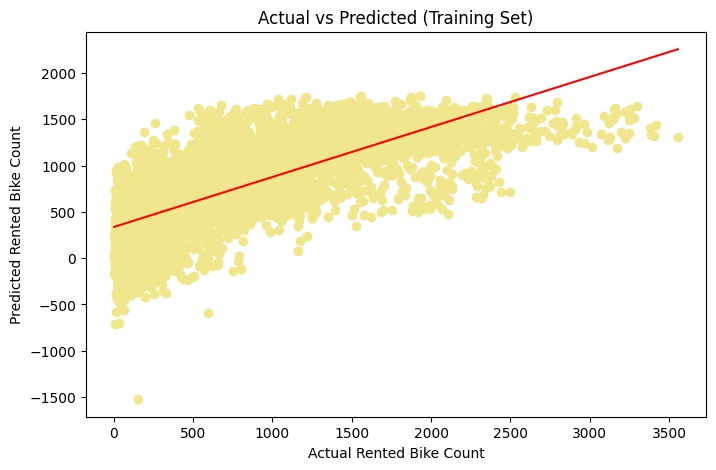

In [198]:
plt.figure(figsize=(8, 5))
plt.scatter(y_train, y_pred_train, color="khaki")

slope, intercept = np.polyfit(y_train, y_pred_train, 1)
x_line = np.array([y_train.min(), y_train.max()])
plt.plot(x_line, slope * x_line + intercept, color="red")

plt.title("Actual vs Predicted (Training Set)")
plt.xlabel("Actual Rented Bike Count")
plt.ylabel("Predicted Rented Bike Count")
plt.show()

In [199]:
print("R2 :", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred)))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred))))

R2 : 0.557
MAE: 321
RMSE: 417


In [200]:
# Let's transform the hour in categories instead of numbers. Since there's a peak (8am and 6pm), the model might perform better:

df_final["Hour"].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23])

In [201]:
df_final["Hour Obj"] = df_final["Hour"].astype(str)
df_final["Hour Obj"].head()

,Hour Obj
0,0
1,1
2,2
3,3
4,4


In [202]:
cat_hour = pd.get_dummies(df_final["Hour Obj"], drop_first=True)
cat_hour

,1,10,11,12,13,14,15,16,17,18,...,21,22,23,3,4,5,6,7,8,9
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,True,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8756,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8757,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
8758,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False


In [203]:
df_new = pd.merge(df_final, cat_hour, left_index=True, right_index=True)
df_new.head()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Holiday,...,21,22,23,3,4,5,6,7,8,9
0,254,0,-5.2,37,2.2,2000,0.0,0.0,0.0,0,...,False,False,False,False,False,False,False,False,False,False
1,204,1,-5.5,38,0.8,2000,0.0,0.0,0.0,0,...,False,False,False,False,False,False,False,False,False,False
2,173,2,-6.0,39,1.0,2000,0.0,0.0,0.0,0,...,False,False,False,False,False,False,False,False,False,False
3,107,3,-6.2,40,0.9,2000,0.0,0.0,0.0,0,...,False,False,False,True,False,False,False,False,False,False
4,78,4,-6.0,36,2.3,2000,0.0,0.0,0.0,0,...,False,False,False,False,True,False,False,False,False,False


In [204]:
X = df_new.drop(["Rented Bike Count", "Hour", "Hour Obj"], axis=1)
y = df_new["Rented Bike Count"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)

print(f"Train score: {r2_train}")
print(f"Test score: {r2_test}")

print('-'*20)

print('Intercept: {}'.format(model.intercept_))
print("Coeficiente: {}".format(model.coef_))
print('RMSE: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))
print('R2: {}'.format(r2_train))

Train score: 0.662586119723064
Test score: 0.6645847149923652
--------------------
Intercept: 969.1923568179611
Coeficiente: [ 2.35527069e+01 -7.12640929e+00 -1.47163191e+00 -3.02236519e-03
  7.31494319e+01 -6.49646597e+01  2.18831890e+01 -1.31195271e+02
 -1.01643001e+00  4.57861114e+00 -1.46987874e+01 -1.34332719e+02
 -1.39489699e+02 -3.41204029e+02 -1.12262799e+02 -2.14439021e+02
 -2.28511533e+02 -1.77598602e+02 -1.85278151e+02 -2.10767694e+02
 -9.90503462e+01  5.08244908e+01  3.34081458e+02  7.83006106e+02
  5.25892141e+02 -2.15338293e+02  4.40511759e+02  4.30369074e+02
  3.36026860e+02  1.06886739e+02 -3.05158857e+02 -3.60291646e+02
 -3.51575550e+02 -1.87226751e+02  1.21731781e+02  5.07503714e+02
  2.68360715e+01]
RMSE: 375.34324028452886
R2: 0.662586119723064


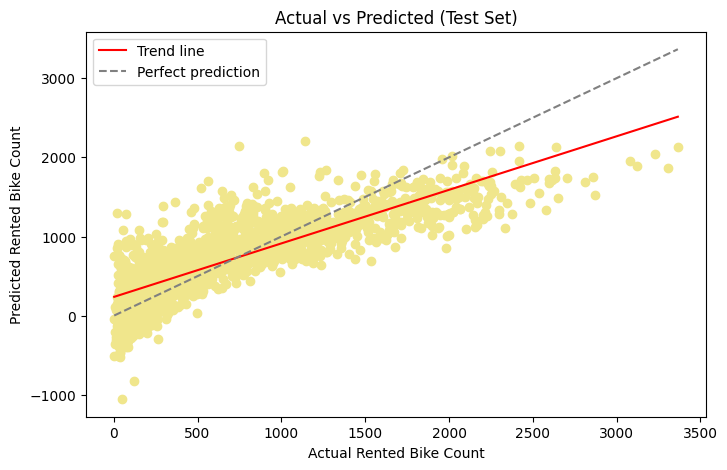

In [205]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color="khaki")

# Trend line (same as trendline="ols" in plotly)
slope, intercept = np.polyfit(y_test, y_pred, 1)
x_line = np.array([y_test.min(), y_test.max()])
plt.plot(x_line, slope * x_line + intercept, color="red", label="Trend line")
plt.plot(x_line, x_line, color="gray", linestyle="--", label="Perfect prediction")

plt.title("Actual vs Predicted (Test Set)")
plt.xlabel("Actual Rented Bike Count")
plt.ylabel("Predicted Rented Bike Count")
plt.legend()
plt.show()

Explanation:

The model is a formula:

- bikes = intercept + coef₁·Temperature + coef₂·Rain + coef₃·Hour_8 + ...

Intercept: the prediction when every feature is 0. With dummies, that means the baseline case: the dropped categories (e.g. hour 0, Autumn, no holiday, Monday) at 0°C, no rain, and so on. Alone, it often doesn't mean much. It's the starting point. In our case, is 815 bikes rented.


In [206]:
df_new["Rented Bike Count"].describe()

,Rented Bike Count
count,8465.000000
mean,729.156999
std,642.351166
min,2.000000
25%,214.000000
50%,542.000000
75%,1084.000000
max,3556.000000


Coefficient: how much the prediction changes when that feature goes up by 1, with everything else unchanged.

- Temperature = 23 → each extra degree adds about 23 bikes per hour
- Rainfall = −64 → each extra mm of rain removes about 64 bikes per hour
- Hour_8 = +236 → at 8am, about 236 more bikes than the baseline hour (midnight)

In [207]:
# model.coef_ is in the same order as your columns in X. Put the two side by side:

for col, coe in zip(X_train.columns, model.coef_):
  print(col, coe)

Temperature(°C) 23.552706884638717
Humidity(%) -7.126409285241106
Wind speed (m/s) -1.4716319138247955
Visibility (10m) -0.0030223651902842453
Solar Radiation (MJ/m2) 73.14943193690142
Rainfall(mm) -64.96465971482205
Snowfall (cm) 21.883188977204604
Holiday -131.19527065640253
Day -1.0164300145569474
Month 4.57861114042102
Day of the week -14.698787426320248
Seasons_Spring -134.3327186223838
Seasons_Summer -139.48969920413504
Seasons_Winter -341.2040286234683
1 -112.26279925947338
10 -214.43902124291958
11 -228.51153347205278
12 -177.59860235695197
13 -185.27815078480134
14 -210.76769390022594
15 -99.05034623142599
16 50.82449081574873
17 334.08145797828087
18 783.0061060995803
19 525.8921414884637
2 -215.33829293260598
20 440.511758822728
21 430.3690744606591
22 336.02686020043126
23 106.8867386778975
3 -305.15885650351305
4 -360.2916463152475
5 -351.5755496744068
6 -187.22675066762096
7 121.73178093483857
8 507.5037138326041
9 26.836071544723143


In [208]:
print("R2 :", round(r2_score(y_test, y_pred), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred)))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred))))

R2 : 0.665
MAE: 274
RMSE: 363


In [209]:
df_new["Rented Bike Count"].mean()

np.float64(729.1569994093326)

- MAE: The model was off by 274 bikes per hour on average.

RMSE (Root Mean Squared Error)
Square the errors, average them, then take the square root: √((2,500 + 2,500 + 10,000 + 40,000) / 4) = ~117 (for example).
It's in bikes too, but squaring makes big misses count much more. The −200 error pushed it above the MAE.

RMSE close to MAE → errors are similar in size
RMSE much bigger than MAE → a few large misses

- RMSE: 363: we missed a few large misses.

Use RMSE when big errors are especially costly (e.g. an empty station at rush hour).

R² compares your model to a lazy model that always predicts the average (here 729).

Lazy model's squared errors: X
Your model's squared errors: Y
R² = 1 − Y / X = 0.665

"The model explains 66% of the variation in demand."

1 = perfect
0 = no better than guessing the average
Below 0 = worse than guessing the average

How to know if your model "got better"

Compare the test metrics before and after:

R² up
MAE and RMSE down

Also judge MAE against the typical value. Average demand is around 729 bikes per hour, so an MAE of 200 means you're off by roughly 30%.

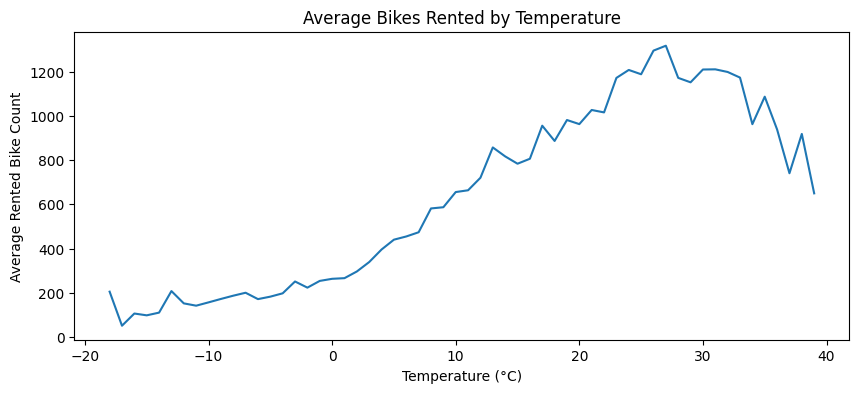

In [210]:
curve = df_new.groupby(df_new["Temperature(°C)"].round())["Rented Bike Count"].mean()

plt.figure(figsize=(10, 4))
plt.plot(curve.index, curve.values)
plt.title("Average Bikes Rented by Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Average Rented Bike Count")
plt.show()

In [211]:
Xt = df_new[["Temperature(°C)"]]          # double brackets → keeps it as a table
y = df_new["Rented Bike Count"]

Xt_train, Xt_test, y_train, y_test = train_test_split(Xt, y, test_size=0.2, random_state=42)

line = LinearRegression().fit(Xt_train, y_train)
print("Straight line R2:", round(r2_score(y_test, line.predict(Xt_test)), 3))

Straight line R2: 0.325


In [212]:
Xt2 = Xt.copy()
Xt2["Temp2"] = Xt2["Temperature(°C)"] ** 2      # the new column

Xt2_train, Xt2_test, y_train, y_test = train_test_split(Xt2, y, test_size=0.2, random_state=42)

curve_model = LinearRegression().fit(Xt2_train, y_train)

print("Curve R2:", round(r2_score(y_test, curve_model.predict(Xt2_test)), 3))
print("Weights:", curve_model.coef_)

Curve R2: 0.325
Weights: [32.24181234 -0.09222995]


In [213]:
# Temp + temp² + temp³
Xt3 = Xt2.copy()
Xt3["Temp3"] = Xt3["Temperature(°C)"] ** 3

Xt3_train, Xt3_test, y_train, y_test = train_test_split(Xt3, y, test_size=0.2, random_state=42)

curve3_model = LinearRegression().fit(Xt3_train, y_train)
print("Curve (temp³) R2:", round(r2_score(y_test, curve3_model.predict(Xt3_test)), 3))

# Temp + temp² + temp³ + temp⁴
Xt4 = Xt3.copy()
Xt4["Temp4"] = Xt4["Temperature(°C)"] ** 4

Xt4_train, Xt4_test, y_train, y_test = train_test_split(Xt4, y, test_size=0.2, random_state=42)

curve4_model = LinearRegression().fit(Xt4_train, y_train)
print("Curve (temp⁴) R2:", round(r2_score(y_test, curve4_model.predict(Xt4_test)), 3))

# Temp + temp² + temp³ + temp⁴
Xt5 = Xt4.copy()
Xt5["Temp5"] = Xt5["Temperature(°C)"] ** 5

Xt5_train, Xt5_test, y_train, y_test = train_test_split(Xt5, y, test_size=0.2, random_state=42)

curve5_model = LinearRegression().fit(Xt5_train, y_train)
print("Curve (temp5) R2:", round(r2_score(y_test, curve5_model.predict(Xt5_test)), 3))

Curve (temp³) R2: 0.342
Curve (temp⁴) R2: 0.344
Curve (temp5) R2: 0.344


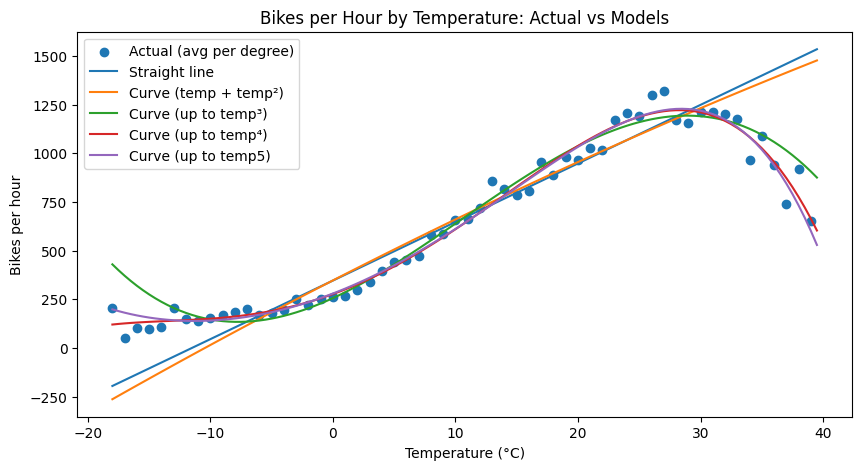

In [214]:
# Smooth range of temperatures, with the same extra columns as each model
temps = pd.DataFrame({"Temperature(°C)": np.arange(-18, 40, 0.5)})
temps2 = temps.copy()
temps2["Temp2"] = temps2["Temperature(°C)"] ** 2
temps3 = temps2.copy()
temps3["Temp3"] = temps3["Temperature(°C)"] ** 3
temps4 = temps3.copy()
temps4["Temp4"] = temps4["Temperature(°C)"] ** 4
temps5 = temps4.copy()
temps5["Temp5"] = temps5["Temperature(°C)"] ** 5

plt.figure(figsize=(10, 5))
plt.scatter(curve.index, curve.values, label="Actual (avg per degree)")
plt.plot(temps["Temperature(°C)"], line.predict(temps), label="Straight line")
plt.plot(temps["Temperature(°C)"], curve_model.predict(temps2), label="Curve (temp + temp²)")
plt.plot(temps["Temperature(°C)"], curve3_model.predict(temps3), label="Curve (up to temp³)")
plt.plot(temps["Temperature(°C)"], curve4_model.predict(temps4), label="Curve (up to temp⁴)")
plt.plot(temps["Temperature(°C)"], curve5_model.predict(temps5), label="Curve (up to temp5)")
plt.title("Bikes per Hour by Temperature: Actual vs Models")
plt.xlabel("Temperature (°C)")
plt.ylabel("Bikes per hour")
plt.legend()
plt.show()

In [215]:
# Let's add temp2 to the model:
X = df_new.drop(["Rented Bike Count", "Hour", "Hour Obj"], axis=1)
X["temperature²"] = Xt2["Temp2"]
y = df_new["Rented Bike Count"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)

print(f"Train score: {r2_train}")
print(f"Test score: {r2_test}")

print('-'*20)

print('Intercept: {}'.format(model.intercept_))
print("Coeficient: {}".format(model.coef_))

print('RMSE train: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))
print('RMSE test: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))

print('R2 train: {}'.format(r2_train))
print('R2 test: {}'.format(r2_test))

print("MAE train:", round(mean_absolute_error(y_train, y_pred_train)))
print("MAE test:", round(mean_absolute_error(y_test, y_pred)))

Train score: 0.6639875791836738
Test score: 0.6649929934068237
--------------------
Intercept: 932.0973986987492
Coeficient: [ 2.86493190e+01 -7.15452328e+00  7.78604875e-01  8.68355332e-03
  8.40025789e+01 -6.47573140e+01  2.67812481e+01 -1.37986287e+02
 -1.01784089e+00  4.47836568e+00 -1.50415934e+01 -1.36225126e+02
 -9.85277747e+01 -3.02858292e+02 -1.11548925e+02 -2.23436210e+02
 -2.40524177e+02 -1.93285950e+02 -2.00171000e+02 -2.23897069e+02
 -1.09998981e+02  4.42208812e+01  3.30836772e+02  7.83632148e+02
  5.27275329e+02 -2.12721809e+02  4.41319924e+02  4.30508333e+02
  3.36118884e+02  1.07908880e+02 -3.02860450e+02 -3.57031751e+02
 -3.48965731e+02 -1.83714009e+02  1.26423429e+02  5.09417630e+02
  2.38605459e+01 -2.22976030e-01]
RMSE train: 374.5629290375716
RMSE test: 374.5629290375716
R2 train: 0.6639875791836738
R2 test: 0.6649929934068237
MAE train: 283
MAE test: 276


In [217]:
# Let's add temp3 to the model:
X = df_new.drop(["Rented Bike Count", "Hour", "Hour Obj"], axis=1)
X["temperature²"] = Xt2["Temp2"]
X["temperature³"] = Xt3["Temp3"]
y = df_new["Rented Bike Count"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)

model = LinearRegression().fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_train = model.predict(X_train)

r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred)

print(f"Train score: {r2_train}")
print(f"Test score: {r2_test}")

print('-'*20)

print('Intercept: {}'.format(model.intercept_))
print("Coeficient: {}".format(model.coef_))

print('RMSE train: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))
print('RMSE test: {}'.format(np.sqrt(mean_squared_error(y_train, y_pred_train))))

print('R2 train: {}'.format(r2_train))
print('R2 test: {}'.format(r2_test))

print("MAE train:", round(mean_absolute_error(y_train, y_pred_train)))
print("MAE test:", round(mean_absolute_error(y_test, y_pred)))

Train score: 0.6927169100465436
Test score: 0.6955878313152313
--------------------
Intercept: 810.3477060506315
Coeficient: [ 2.71879051e+01 -7.67035739e+00 -6.97967932e+00 -1.49365499e-02
  9.43181059e+01 -7.12174698e+01  3.66239827e+01 -1.23094777e+02
 -1.50884521e+00  9.89565227e+00 -1.43556569e+01 -1.09093164e+02
 -6.26829712e+01 -2.20161043e+02 -1.07177753e+02 -2.31531192e+02
 -2.47704675e+02 -1.94892575e+02 -1.93333010e+02 -2.05018247e+02
 -8.89874638e+01  6.94973371e+01  3.63801203e+02  8.13195830e+02
  5.47426680e+02 -2.08307535e+02  4.48188402e+02  4.38760770e+02
  3.41670771e+02  1.08392435e+02 -3.02191685e+02 -3.59332178e+02
 -3.51503474e+02 -1.86469381e+02  1.14756674e+02  4.93491360e+02
  1.12300318e+01  1.48674238e+00 -5.27293422e-02]
RMSE train: 358.1924746321036
RMSE test: 358.1924746321036
R2 train: 0.6927169100465436
R2 test: 0.6955878313152313
MAE train: 271
MAE test: 263


## Conclusion

**Can we predict how many bikes will be rented in a given hour?** Yes, reasonably well. The best model explains about 69% of the change in hourly demand. On average it is off by about 263 bikes per hour, which is roughly 36% of the average demand (729 bikes).

**How the models compare (test set):**

| Model | R² | MAE |
|---|---|---|
| Hour as a number | 0.557 | 321 |
| Hour as categories (dummies) | 0.665 | 274 |
| + temperature² | 0.665 | 276 |
| + temperature³ | 0.677 | 263 |

- **Treating the hour as categories gave the biggest improvement.** Demand doesn't rise steadily through the day. It has two peaks, around 8am and 6pm. As a single number, the hour can't capture that, but dummies can.
- **Adding curved temperature terms helped only a little.** The R² went from 0.665 to 0.695.
- **Train and test scores are almost the same**, so the model is not overfitting.

**What drives demand:**
- **Time of day matters most.** Compared with midnight, about 508 more bikes are rented at 8am and about 783 more at 6pm. This points to people commuting to and from work.
- **Warmer weather means more rentals:** about 24 more bikes per hour for each extra degree.
- **Rain lowers demand:** about 65 fewer bikes per hour for each mm of rain.
- **Holidays have lower demand:** about 131 fewer bikes per hour, which also fits the commuting pattern.
- **Winter has the lowest demand** of all seasons.

**Limitations:**
- The model is still off by about 37% on average, and it misses some large peaks (RMSE is higher than MAE).
- A linear model applies the same hour effect to every day, but commuting peaks only happen on weekdays.
- The data was split at random. Neighbouring hours are very similar, so the test score may look better than it would on truly new days.